In [1]:
import numpy as np
import sys
from pathlib import Path

ROOT = Path.cwd().resolve().parents[1]
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

Tracing control amplitude graph.


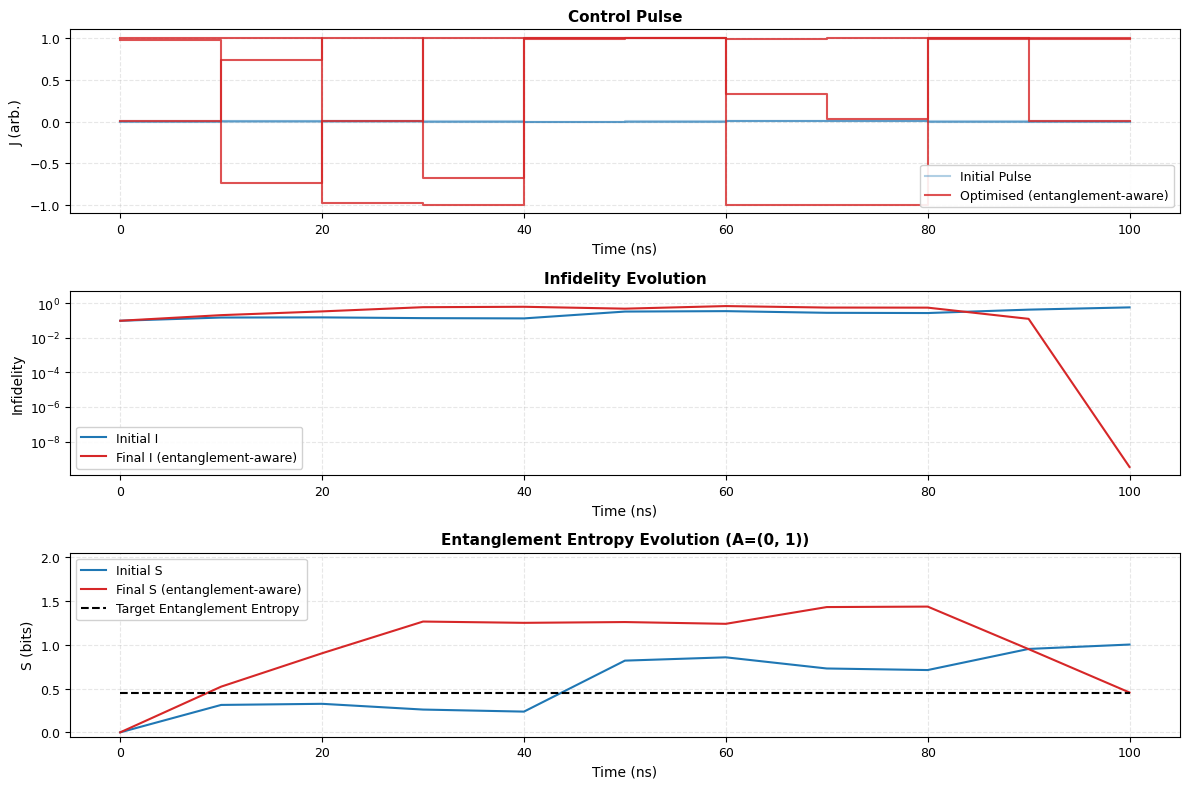

In [2]:
from pulse_vqe_entanglement.dataclasses import SimulationConfig
from pulse_vqe_entanglement.dqe_optimisation import dqe_optimisation, basis_state
from pulse_vqe_entanglement.plotting import plot_dqe_optimisation

config = SimulationConfig(
    zeeman_splittings=np.array([0.0, 8.0, 16.0, 24.0]), 
    initial_state=basis_state(4, "0011"),
    theta_target=0.1 * np.pi,
    n_time_steps=10,
    T=100.0,
    max_drive_strength=0.0,
    J_max=10.0,
    J_min=0.0,
    J_init_scale=1e-2,
    gtol=1e-12,
    maxiter=200,
    run_mode="infidelity",
    init_seed=123,

    # entropy settings
    entropy_subsystem=(0, 1),   # S(12|34); change to (0,2) etc if needed
    S_max=0.05,
    eps_infidelity=1e-8,
    rho=10.0,
    dual_lr=1e8,
    n_outer=10,
    inner_maxiter=200,
    fd_eps=1e-5,
)

res = dqe_optimisation(config)
plot_dqe_optimisation(res)